In [19]:
import requests
import pandas as pd

In [20]:
from getpass import getpass

api_key = getpass("Enter your ICAO API key: ")

Enter your ICAO API key: ··········


In [21]:
url = "https://dataservices.icao.int/api/accidents"

params = {
    "api_key": api_key,
    "format": "json",
    "StateOfOccurrence": "MYS"
}

response = requests.get(url, params=params)

print("Status code:", response.status_code)
print(response.text[:1000])

Status code: 200
[
  {
    "Date": "\"2008-05-31T00:00:00.000Z\"",
    "StateOfOccurrence": "MYS",
    "Location": "Sibu Ap.,  Sibu, MY",
    "Model": "FOKKER F27 50",
    "Registration": "9M-MGJ",
    "Operator": "",
    "StateOfOperator": "",
    "StateOfRegistry": "MYS",
    "FlightPhase": "Approach",
    "Class": "Accident",
    "Fatalities": "0",
    "Over2250": "true",
    "Over5700": "true",
    "ScheduledCommercial": "true",
    "InjuryLevel": "None",
    "TypeDesignator": "F27",
    "Helicopter": "false",
    "Airplane": "true",
    "Engines": "2",
    "EngineType": "Turboprop",
    "Official": "",
    "OccCats": "[\"SCF-NP\"]",
    "Risk": "SCF",
    "Year": "2008"
  },
  {
    "Date": "\"2008-09-13T00:00:00.000Z\"",
    "StateOfOccurrence": "MYS",
    "Location": "Ba Kelalan",
    "Model": "DE HAVILLAND DHC6 300",
    "Registration": "9M-MDN",
    "Operator": "MASwings",
    "StateOfOperator": "",
    "StateOfRegistry": "MYS",
    "FlightPhase": "Landing",


In [22]:
df_icao = pd.DataFrame(data)
df_icao.head()

,Date,StateOfOccurrence,Location,Model,Registration,Operator,StateOfOperator,StateOfRegistry,FlightPhase,Class,...,InjuryLevel,TypeDesignator,Helicopter,Airplane,Engines,EngineType,Official,OccCats,Risk,Year
0,"""2008-05-31T00:00:00.000Z""",MYS,"Sibu Ap., Sibu, MY",FOKKER F27 50,9M-MGJ,,,MYS,Approach,Accident,...,None,F27,false,true,2,Turboprop,,"[""SCF-NP""]",SCF,2008
1,"""2008-09-13T00:00:00.000Z""",MYS,Ba Kelalan,DE HAVILLAND DHC6 300,9M-MDN,MASwings,,MYS,Landing,Accident,...,Minor,VNOM,false,true,1,Jet,,"[""USOS""]",RS,2008
2,"""2009-10-02T00:00:00.000Z""",MYS,Kuching (WBGG),BOEING 737 300,9M-MMR,Malaysia Malaysian Airlines System,MYS,MYS,Standing,Accident,...,None,B37M,false,true,2,Jet,,"[""SCF-NP""]",SCF,2009
3,"""2010-06-21T00:00:00.000Z""",MYS,,AIRBUS A320,9M-AHK,,,MYS,Landing,Accident,...,None,A320,false,true,2,Jet,,[],RS,2010
4,"""2010-06-25T00:00:00.000Z""",MYS,,SIKORSKY S64,N229AC,,,USA,Manoeuvring,Accident,...,Fatal,S64,true,false,2,Turboprop,,[],,2010


In [23]:
print("Number of records:", len(df_icao))
print("Columns:")
print(df_icao.columns.tolist())

Number of records: 18
Columns:
['Date', 'StateOfOccurrence', 'Location', 'Model', 'Registration', 'Operator', 'StateOfOperator', 'StateOfRegistry', 'FlightPhase', 'Class', 'Fatalities', 'Over2250', 'Over5700', 'ScheduledCommercial', 'InjuryLevel', 'TypeDesignator', 'Helicopter', 'Airplane', 'Engines', 'EngineType', 'Official', 'OccCats', 'Risk', 'Year']


In [24]:
columns_to_view = [
    "Date",
    "Year",
    "Location",
    "Model",
    "Operator",
    "FlightPhase",
    "Class",
    "Fatalities",
    "InjuryLevel",
    "OccCats",
    "Risk"
]

df_icao[columns_to_view]

,Date,Year,Location,Model,Operator,FlightPhase,Class,Fatalities,InjuryLevel,OccCats,Risk
0,"""2008-05-31T00:00:00.000Z""",2008,"Sibu Ap., Sibu, MY",FOKKER F27 50,,Approach,Accident,0,None,"[""SCF-NP""]",SCF
1,"""2008-09-13T00:00:00.000Z""",2008,Ba Kelalan,DE HAVILLAND DHC6 300,MASwings,Landing,Accident,0,Minor,"[""USOS""]",RS
2,"""2009-10-02T00:00:00.000Z""",2009,Kuching (WBGG),BOEING 737 300,Malaysia Malaysian Airlines System,Standing,Accident,0,None,"[""SCF-NP""]",SCF
3,"""2010-06-21T00:00:00.000Z""",2010,,AIRBUS A320,,Landing,Accident,0,None,[],RS
4,"""2010-06-25T00:00:00.000Z""",2010,,SIKORSKY S64,,Manoeuvring,Accident,1,Fatal,[],
5,"""2010-07-07T00:00:00.000Z""",2010,,AEROSPATIALE AS355,,En route,Accident,0,None,[],
6,"""2011-01-10T00:00:00.000Z""",2011,Kuching Apt,AIRBUS A320,AirAsia,Landing,Accident,0,None,"[""RE""]",RS
7,"""2011-03-24T00:00:00.000Z""",2011,,BELL 206,,Standing,Accident,0,None,[],RS
8,"""2011-04-11T00:00:00.000Z""",2011,"Sibu, Malaysia",BELL 206 B,Malaysia Sabah Air,Take-off,Accident,1,Fatal,[],LOC-I
9,"""2011-08-24T00:00:00.000Z""",2011,Lawas Airport (LWY),DHC-6 Twin Otter 310,MASwings,Landing,Accident,0,,[],RS


In [25]:
print("Earliest year:", df_icao["Year"].min())
print("Latest year:", df_icao["Year"].max())

print("\nAccidents by year:")
print(df_icao["Year"].value_counts().sort_index())

Earliest year: 2008
Latest year: 2019

Accidents by year:
Year
2008    2
2009    1
2010    3
2011    4
2013    1
2014    2
2015    1
2016    1
2017    2
2019    1
Name: count, dtype: int64


In [26]:
print("Total fatalities:", df_icao["Fatalities"].sum())

print("\nFatalities by accident:")
print(
    df_icao[
        ["Date", "Location", "Model", "Fatalities"]
    ].sort_values(
        "Fatalities",
        ascending=False
    )
)

Total fatalities: 0000100010206000

Fatalities by accident:
                          Date  \
13  "2015-04-04T00:00:00.000Z"   
10  "2013-10-10T00:00:00.000Z"   
4   "2010-06-25T00:00:00.000Z"   
8   "2011-04-11T00:00:00.000Z"   
0   "2008-05-31T00:00:00.000Z"   
1   "2008-09-13T00:00:00.000Z"   
16  "2017-09-24T00:00:00.000Z"   
14  "2016-05-11T00:00:00.000Z"   
11  "2014-01-10T00:00:00.000Z"   
9   "2011-08-24T00:00:00.000Z"   
7   "2011-03-24T00:00:00.000Z"   
6   "2011-01-10T00:00:00.000Z"   
5   "2010-07-07T00:00:00.000Z"   
3   "2010-06-21T00:00:00.000Z"   
2   "2009-10-02T00:00:00.000Z"   
17  "2019-03-18T00:00:00.000Z"   
12  "2014-03-26T00:00:00.000Z"   
15  "2017-04-08T00:00:00.000Z"   

                                             Location  \
13                                   Semenyih, Kajang   
10                                              KUDAT   
4                                                       
8                                      Sibu, Malaysia   
0       

In [27]:
print(df_icao["OccCats"].value_counts())

OccCats
[]               11
["SCF-NP"]        2
["USOS"]          1
["RE"]            1
["ADRM","RE"]     1
["LOC-I"]         1
["UNK"]           1
Name: count, dtype: int64


In [28]:
print(df_icao["FlightPhase"].value_counts())

FlightPhase
Landing        9
En route       3
Standing       2
Approach       1
Manoeuvring    1
Take-off       1
               1
Name: count, dtype: int64


In [29]:
missing = df_icao[
    [
        "Year",
        "FlightPhase",
        "Fatalities",
        "InjuryLevel",
        "OccCats",
        "Risk"
    ]
].isna().sum()

print(missing)

Year           0
FlightPhase    0
Fatalities     0
InjuryLevel    0
OccCats        0
Risk           0
dtype: int64


In [30]:
print("Earliest year:", df_icao["Year"].min())
print("Latest year:", df_icao["Year"].max())

print("\nAccidents by year:")
print(df_icao["Year"].value_counts().sort_index())

Earliest year: 2008
Latest year: 2019

Accidents by year:
Year
2008    2
2009    1
2010    3
2011    4
2013    1
2014    2
2015    1
2016    1
2017    2
2019    1
Name: count, dtype: int64


In [31]:
print("Occurrence categories:")
print(df_icao["OccCats"].value_counts())

Occurrence categories:
OccCats
[]               11
["SCF-NP"]        2
["USOS"]          1
["RE"]            1
["ADRM","RE"]     1
["LOC-I"]         1
["UNK"]           1
Name: count, dtype: int64


In [32]:
print("Flight phases:")
print(df_icao["FlightPhase"].value_counts())

Flight phases:
FlightPhase
Landing        9
En route       3
Standing       2
Approach       1
Manoeuvring    1
Take-off       1
               1
Name: count, dtype: int64


In [33]:
df_icao["FlightPhase_clean"] = (
    df_icao["FlightPhase"]
    .replace("", "Not recorded")
    .fillna("Not recorded")
)

df_icao["OccCats_clean"] = (
    df_icao["OccCats"]
    .replace("[]", "No category returned")
    .replace("", "No category returned")
    .fillna("No category returned")
)

print(df_icao["FlightPhase_clean"].value_counts())
print()
print(df_icao["OccCats_clean"].value_counts())

FlightPhase_clean
Landing         9
En route        3
Standing        2
Approach        1
Manoeuvring     1
Take-off        1
Not recorded    1
Name: count, dtype: int64

OccCats_clean
No category returned    11
["SCF-NP"]               2
["USOS"]                 1
["RE"]                   1
["ADRM","RE"]            1
["LOC-I"]                1
["UNK"]                  1
Name: count, dtype: int64


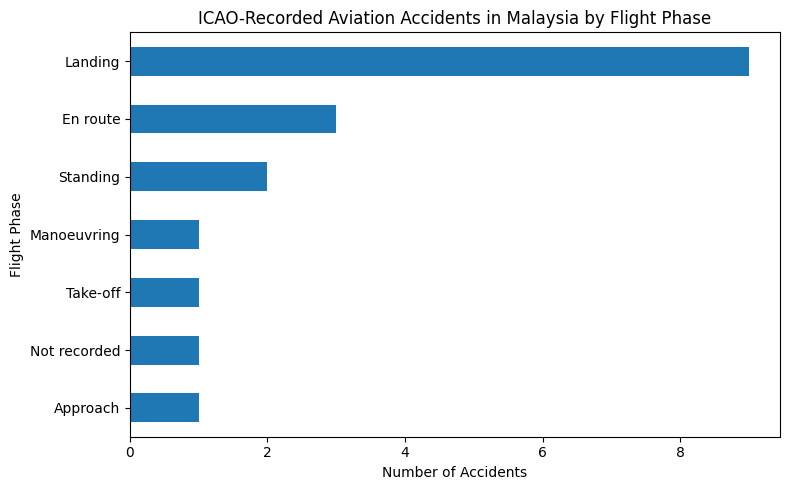

In [34]:
import matplotlib.pyplot as plt

flight_phase_counts = (
    df_icao["FlightPhase_clean"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(8, 5))

flight_phase_counts.plot(kind="barh")

plt.xlabel("Number of Accidents")
plt.ylabel("Flight Phase")
plt.title("ICAO-Recorded Aviation Accidents in Malaysia by Flight Phase")

plt.tight_layout()
plt.savefig(
    "malaysia_accidents_by_flight_phase.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
total_accidents = len(df_icao)

landing_accidents = (
    df_icao["FlightPhase_clean"] == "Landing"
).sum()

landing_percentage = (
    landing_accidents / total_accidents
) * 100

print("Total accidents:", total_accidents)
print("Landing accidents:", landing_accidents)
print(
    "Percentage during landing:",
    round(landing_percentage, 1),
    "%"
)

Total accidents: 18
Landing accidents: 9
Percentage during landing: 50.0 %


In [36]:
print("Total fatalities:", df_icao["Fatalities"].sum())
print()

print("Fatalities by accident:")
print(
    df_icao[
        ["Date", "Location", "Model", "FlightPhase_clean", "Fatalities", "InjuryLevel"]
    ]
    .sort_values("Fatalities", ascending=False)
)

Total fatalities: 0000100010206000

Fatalities by accident:
                          Date  \
13  "2015-04-04T00:00:00.000Z"   
10  "2013-10-10T00:00:00.000Z"   
4   "2010-06-25T00:00:00.000Z"   
8   "2011-04-11T00:00:00.000Z"   
0   "2008-05-31T00:00:00.000Z"   
1   "2008-09-13T00:00:00.000Z"   
16  "2017-09-24T00:00:00.000Z"   
14  "2016-05-11T00:00:00.000Z"   
11  "2014-01-10T00:00:00.000Z"   
9   "2011-08-24T00:00:00.000Z"   
7   "2011-03-24T00:00:00.000Z"   
6   "2011-01-10T00:00:00.000Z"   
5   "2010-07-07T00:00:00.000Z"   
3   "2010-06-21T00:00:00.000Z"   
2   "2009-10-02T00:00:00.000Z"   
17  "2019-03-18T00:00:00.000Z"   
12  "2014-03-26T00:00:00.000Z"   
15  "2017-04-08T00:00:00.000Z"   

                                             Location  \
13                                   Semenyih, Kajang   
10                                              KUDAT   
4                                                       
8                                      Sibu, Malaysia   
0       

In [37]:
injury_counts = df_icao["InjuryLevel"].value_counts()

print("Injury level counts:")
print(injury_counts)

Injury level counts:
InjuryLevel
None     6
         6
Fatal    4
Minor    2
Name: count, dtype: int64


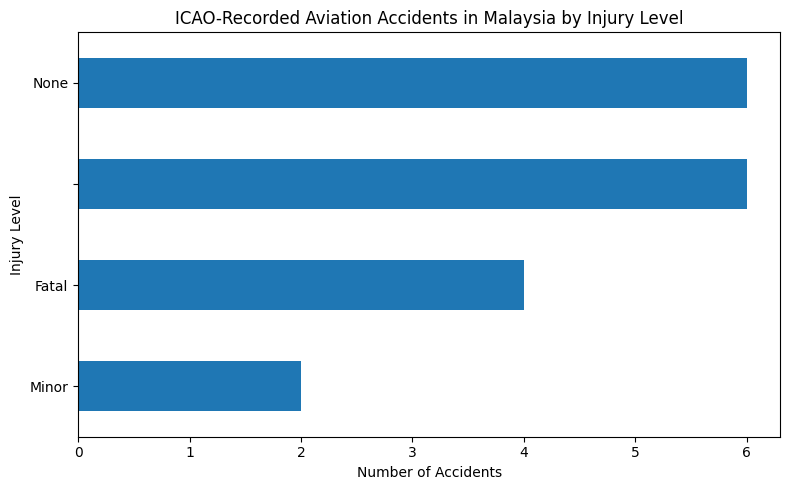

In [38]:
import matplotlib.pyplot as plt

injury_counts = (
    df_icao["InjuryLevel"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(8, 5))

injury_counts.plot(kind="barh")

plt.xlabel("Number of Accidents")
plt.ylabel("Injury Level")
plt.title("ICAO-Recorded Aviation Accidents in Malaysia by Injury Level")

plt.tight_layout()

plt.savefig(
    "malaysia_accidents_by_injury_level.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
fatalities_by_phase = (
    df_icao.groupby("FlightPhase_clean")["Fatalities"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
    .round(2)
)

fatalities_by_phase

,count,sum,mean
FlightPhase_clean,,,
En route,2,6.0,3.00
Landing,8,2.0,0.25
Manoeuvring,1,1.0,1.00
Take-off,1,1.0,1.00
Approach,1,0.0,0.00
Not recorded,1,0.0,0.00
Standing,2,0.0,0.00


In [40]:
df_icao["Fatalities"] = pd.to_numeric(
    df_icao["Fatalities"],
    errors="coerce"
)

print(df_icao["Fatalities"].dtype)
print(df_icao["Fatalities"].isna().sum())

float64
2


In [42]:
fatalities_by_phase = (
    df_icao.groupby("FlightPhase_clean")
    .agg(
        accidents=("Fatalities", "size"),
        fatalities_recorded=("Fatalities", "count"),
        total_fatalities=("Fatalities", "sum"),
        mean_fatalities=("Fatalities", "mean")
    )
    .sort_values("total_fatalities", ascending=False)
    .round(2)
)

fatalities_by_phase

,accidents,fatalities_recorded,total_fatalities,mean_fatalities
FlightPhase_clean,,,,
En route,3,2,6.0,3.00
Landing,9,8,2.0,0.25
Manoeuvring,1,1,1.0,1.00
Take-off,1,1,1.0,1.00
Approach,1,1,0.0,0.00
Not recorded,1,1,0.0,0.00
Standing,2,2,0.0,0.00


In [43]:
missing_fatalities = df_icao[
    df_icao["Fatalities"].isna()
][
    [
        "Date",
        "Location",
        "Model",
        "FlightPhase_clean",
        "InjuryLevel",
        "Class",
        "OccCats_clean"
    ]
]

missing_fatalities

,Date,Location,Model,FlightPhase_clean,InjuryLevel,Class,OccCats_clean
12,"""2014-03-26T00:00:00.000Z""",N of Kuala Lumpur-Sultan Abdul Aziz Shah Airpo...,ATR 72-212A (ATR 72-600),En route,,Accident,No category returned
15,"""2017-04-08T00:00:00.000Z""",Sibu Airport (SBW),Boeing 737-8H6 (WL),Landing,,Accident,No category returned


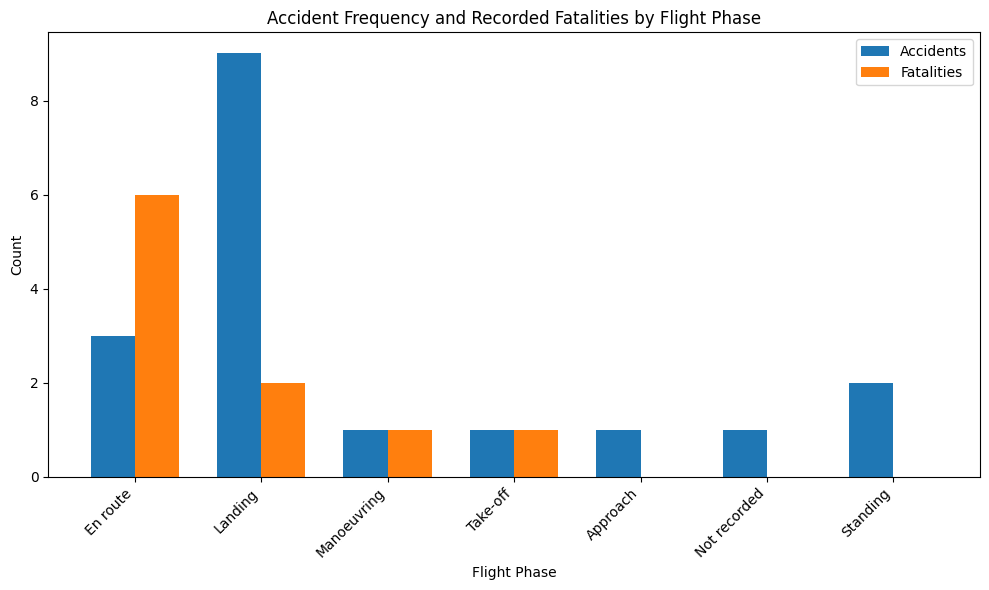

In [44]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = fatalities_by_phase.copy()

phases = plot_data.index
accidents = plot_data["accidents"]
fatalities = plot_data["total_fatalities"]

x = np.arange(len(phases))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    accidents,
    width,
    label="Accidents"
)

plt.bar(
    x + width/2,
    fatalities,
    width,
    label="Fatalities"
)

plt.xticks(
    x,
    phases,
    rotation=45,
    ha="right"
)

plt.ylabel("Count")
plt.xlabel("Flight Phase")
plt.title(
    "Accident Frequency and Recorded Fatalities by Flight Phase"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "accidents_vs_fatalities_by_flight_phase.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
df_icao["Fatalities_verified"] = df_icao["Fatalities"].copy()

df_icao.loc[
    (df_icao["Date"].str.contains("2014-03-26")) &
    (df_icao["Model"].str.contains("ATR")),
    "Fatalities_verified"
] = 0

df_icao.loc[
    (df_icao["Date"].str.contains("2017-04-08")) &
    (df_icao["Model"].str.contains("Boeing 737")),
    "Fatalities_verified"
] = 0

print(df_icao["Fatalities_verified"].isna().sum())

0


In [46]:
fatalities_by_phase_verified = (
    df_icao.groupby("FlightPhase_clean")
    .agg(
        accidents=("Fatalities_verified", "size"),
        total_fatalities=("Fatalities_verified", "sum"),
        mean_fatalities=("Fatalities_verified", "mean")
    )
    .sort_values("total_fatalities", ascending=False)
    .round(2)
)

fatalities_by_phase_verified

,accidents,total_fatalities,mean_fatalities
FlightPhase_clean,,,
En route,3,6.0,2.00
Landing,9,2.0,0.22
Manoeuvring,1,1.0,1.00
Take-off,1,1.0,1.00
Approach,1,0.0,0.00
Not recorded,1,0.0,0.00
Standing,2,0.0,0.00


In [47]:
fatalities_by_phase_verified = (
    df_icao.groupby("FlightPhase_clean")
    .agg(
        accidents=("Fatalities_verified", "size"),
        total_fatalities=("Fatalities_verified", "sum"),
        mean_fatalities=("Fatalities_verified", "mean")
    )
    .sort_values("total_fatalities", ascending=False)
    .round(2)
)

fatalities_by_phase_verified

,accidents,total_fatalities,mean_fatalities
FlightPhase_clean,,,
En route,3,6.0,2.00
Landing,9,2.0,0.22
Manoeuvring,1,1.0,1.00
Take-off,1,1.0,1.00
Approach,1,0.0,0.00
Not recorded,1,0.0,0.00
Standing,2,0.0,0.00


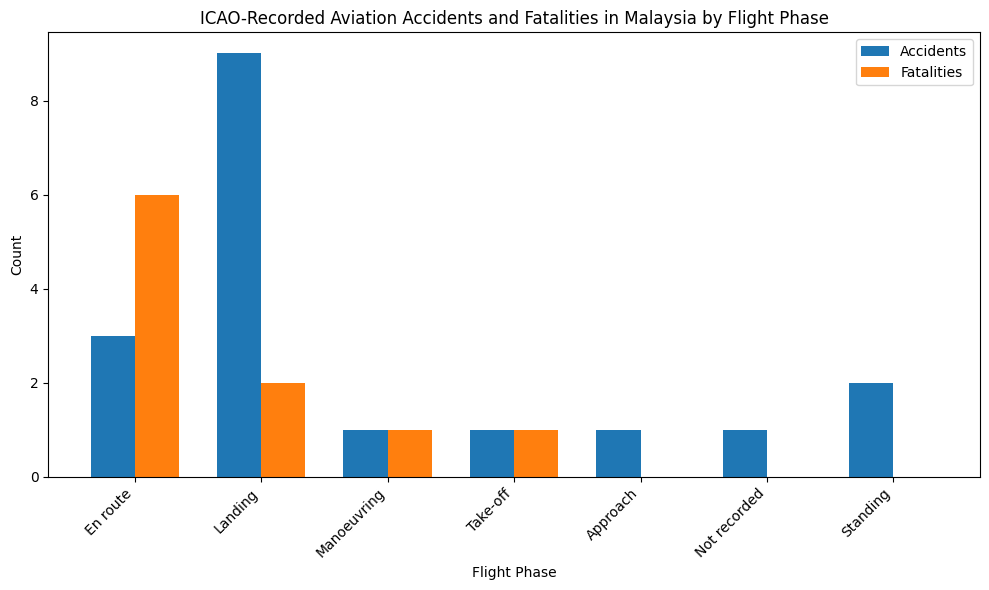

In [48]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = fatalities_by_phase_verified.copy()

phases = plot_data.index
accidents = plot_data["accidents"]
fatalities = plot_data["total_fatalities"]

x = np.arange(len(phases))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    accidents,
    width,
    label="Accidents"
)

plt.bar(
    x + width/2,
    fatalities,
    width,
    label="Fatalities"
)

plt.xticks(
    x,
    phases,
    rotation=45,
    ha="right"
)

plt.ylabel("Count")
plt.xlabel("Flight Phase")
plt.title(
    "ICAO-Recorded Aviation Accidents and Fatalities in Malaysia by Flight Phase"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "accidents_vs_fatalities_by_flight_phase.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
occurrence_labels = {
    '["SCF-NP"]': "System/Component Failure - Non-Powerplant",
    '["USOS"]': "Undershoot/Overshoot",
    '["RE"]': "Runway Excursion",
    '["ADRM","RE"]': "Aerodrome + Runway Excursion",
    '["LOC-I"]': "Loss of Control - In-flight",
    '["UNK"]': "Unknown/Undetermined",
    "No category returned": "No category returned"
}

df_icao["OccurrenceCategory"] = (
    df_icao["OccCats_clean"]
    .replace(occurrence_labels)
)

df_icao["OccurrenceCategory"].value_counts()

,count
OccurrenceCategory,
No category returned,11
System/Component Failure - Non-Powerplant,2
Undershoot/Overshoot,1
Runway Excursion,1
Aerodrome + Runway Excursion,1
Loss of Control - In-flight,1
Unknown/Undetermined,1


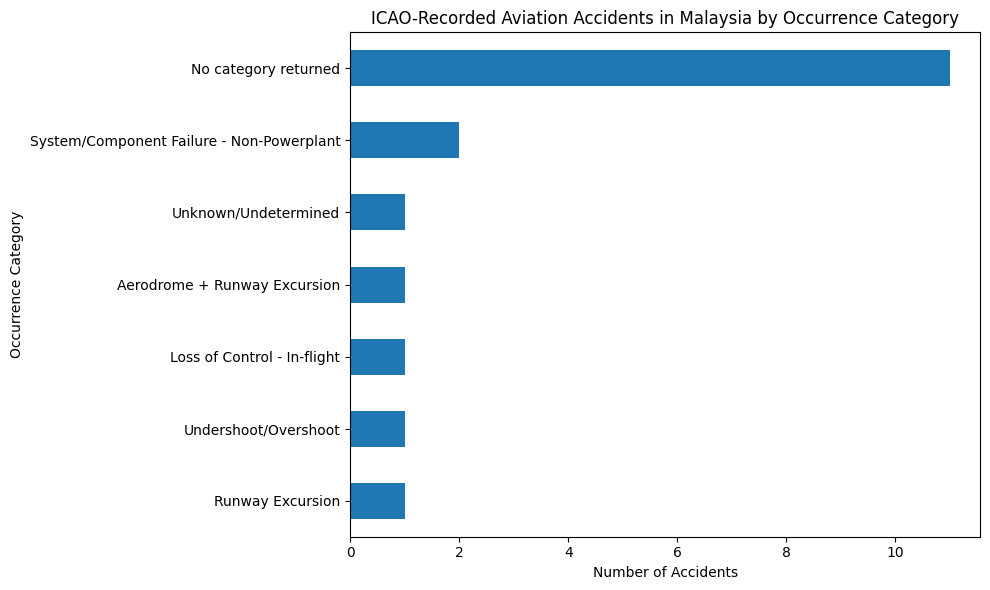

In [50]:
occ_counts = (
    df_icao["OccurrenceCategory"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))

occ_counts.plot(kind="barh")

plt.xlabel("Number of Accidents")
plt.ylabel("Occurrence Category")
plt.title(
    "ICAO-Recorded Aviation Accidents in Malaysia by Occurrence Category"
)

plt.tight_layout()

plt.savefig(
    "malaysia_accidents_by_occurrence_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
df_icao.to_csv(
    "malaysia_icao_accidents_cleaned.csv",
    index=False
)

fatalities_by_phase_verified.to_csv(
    "fatalities_by_flight_phase.csv"
)

print("Files saved successfully.")

Files saved successfully.
